In [1]:
import os
from pathlib import Path
import sys
import calendar
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pystac_client import Client
import rasterio
from rasterio.enums import Resampling
from rasterio.features import geometry_mask
from rasterio.mask import mask
from rasterio.vrt import WarpedVRT
from shapely.geometry import shape
from shapely.ops import unary_union

BASE_DIR = Path("field_classification") if Path("field_classification").exists() else Path(".")
BOUNDARY_FILE = BASE_DIR / "boundary.geojson"
OUT_DIR = BASE_DIR / "enter_data"

YEAR = 2024
MONTHS = tuple(range(3, 11))  # marzec .. pazdziernik
BAND_NAMES = ("RED", "GREEN", "BLUE", "NIR", "SWIR16", "SWIR22", "NDVI", "NDWI", "DOY_SIN", "DOY_COS")

In [2]:
_REQUIRED_ASSETS = ("red", "green", "blue", "nir", "swir16", "swir22")
_SCL_CLOUD_CLASSES = (3, 8, 9, 10)  # cien chmury, chmury o srednim/wysokim prawdop., cirrus


def _scale_s2_reflectance(arr: np.ndarray, asset, src_nodata=None) -> np.ndarray:
    """Przeskaluj piksele Sentinel-2 L2A do odbicia powierzchniowego [0, 1] z uwzglednieniem offsetu."""
    out = arr.astype(np.float32, copy=True)
    out[out == 0] = np.nan
    if src_nodata is not None and np.isfinite(src_nodata):
        out[out == np.float32(src_nodata)] = np.nan

    rb = (getattr(asset, "extra_fields", None) or {}).get("raster:bands") or []
    info = rb[0] if rb and isinstance(rb[0], dict) else {}
    if "nodata" in info and info["nodata"] is not None and np.isfinite(info["nodata"]):
        out[out == np.float32(info["nodata"])] = np.nan

    if "scale" in info or "offset" in info:
        scale = float(info.get("scale", 1.0))
        offset = float(info.get("offset", 0.0))
        out = out * scale + offset
    elif np.any(np.isfinite(out)) and float(np.nanmax(out)) > 1.5:
        out = out * 0.0001

    return np.clip(out, 0.0, 1.0).astype(np.float32)


def _cyclic_doy(dt, year: int) -> tuple[int, float, float]:
    doy = int(dt.timetuple().tm_yday)
    days_in_year = 366 if calendar.isleap(year) else 365
    angle = 2.0 * np.pi * doy / days_in_year
    return doy, float(np.sin(angle)), float(np.cos(angle))


def search_monthly_sentinel2_metadata(
    boundary_file: str | Path,
    year: int = 2024,
    months: tuple[int, ...] = tuple(range(3, 11)),
    max_cc: float = 30.0,
    fallback_max_cc: float = 80.0,
    min_coverage: float = 0.98,
    stac_url: str = "https://earth-search.aws.element84.com/v1",
) -> tuple[pd.DataFrame, dict[int, list]]:
    boundary = gpd.read_file(boundary_file)
    boundary = boundary[boundary.geometry.notna() & ~boundary.geometry.is_empty].copy()
    if boundary.empty:
        raise ValueError(f"Brak poprawnych geometrii w pliku granic: {boundary_file}")

    boundary_wgs84 = boundary.to_crs("EPSG:4326")
    boundary_union = unary_union(boundary_wgs84.geometry)
    search_bbox = [float(v) for v in boundary_wgs84.total_bounds]
    client = Client.open(stac_url)

    monthly_candidates: dict[int, list[dict]] = {m: [] for m in months}
    seen_ids: set[str] = set()

    def _collect(month_subset: tuple[int, ...], cc_limit: float) -> None:
        m_min, m_max = min(month_subset), max(month_subset)
        last_day = calendar.monthrange(year, m_max)[1]
        search = client.search(
            collections=["sentinel-2-l2a"],
            bbox=search_bbox,
            datetime=f"{year}-{m_min:02d}-01/{year}-{m_max:02d}-{last_day:02d}",
            query={"eo:cloud_cover": {"lt": cc_limit}},
        )
        for item in search.items():
            if item.id in seen_ids or item.datetime is None:
                continue
            dt = item.datetime
            if dt.year != year or dt.month not in month_subset:
                continue
            if not all(name in item.assets for name in _REQUIRED_ASSETS):
                continue

            if item.geometry is not None and boundary_union.area > 0:
                cov = float(shape(item.geometry).intersection(boundary_union).area / boundary_union.area)
            else:
                cov = 1.0
            if cov <= 0.0:
                continue

            seen_ids.add(item.id)
            cc = float(item.properties.get("eo:cloud_cover", 100.0))
            monthly_candidates[dt.month].append({
                "item": item,
                "month": dt.month,
                "date": dt.strftime("%Y-%m-%d"),
                "dt": dt,
                "cloud_cover": cc,
                "coverage": cov,
                "mgrs_tile": item.properties.get("grid:code") or item.properties.get("s2:mgrs_tile") or "",
            })

    _collect(tuple(months), max_cc)

    missing_months = tuple(
        m for m in months
        if not any(c["coverage"] >= min_coverage for c in monthly_candidates[m])
    )
    if missing_months and fallback_max_cc > max_cc:
        _collect(missing_months, fallback_max_cc)

    ranked_candidates: dict[int, list] = {}
    meta_rows: list[dict] = []
    for m in months:
        cands = sorted(
            monthly_candidates[m],
            key=lambda c: (c["coverage"] < min_coverage, c["cloud_cover"], -c["coverage"], c["dt"]),
        )
        ranked_candidates[m] = [c["item"] for c in cands]
        if cands:
            best = cands[0]
            doy, doy_sin, doy_cos = _cyclic_doy(best["dt"], year)
            meta_rows.append({
                "month": m,
                "date": best["date"],
                "doy": doy,
                "doy_sin": round(doy_sin, 6),
                "doy_cos": round(doy_cos, 6),
                "cloud_cover": round(best["cloud_cover"], 2),
                "coverage_pct": round(100.0 * best["coverage"], 2),
                "mgrs_tile": best["mgrs_tile"],
                "scene_id": best["item"].id,
                "n_candidates": len(cands),
            })
        else:
            meta_rows.append({
                "month": m, "date": None, "doy": None, "doy_sin": np.nan, "doy_cos": np.nan,
                "cloud_cover": np.nan, "coverage_pct": 0.0, "mgrs_tile": "", "scene_id": None, "n_candidates": 0,
            })

    return pd.DataFrame(meta_rows), ranked_candidates


def _build_ref_grid_from_asset(boundary: gpd.GeoDataFrame, asset) -> dict:
    with rasterio.open(asset.href) as src:
        shapes_proj = [geom.__geo_interface__ for geom in boundary.to_crs(src.crs).geometry]
        clipped, tf = mask(src, shapes_proj, crop=True, nodata=0)
        h, w = clipped.shape[1], clipped.shape[2]
        in_mask = geometry_mask(shapes_proj, out_shape=(h, w), transform=tf, invert=True)
        if not np.any(in_mask):
            in_mask = geometry_mask(shapes_proj, out_shape=(h, w), transform=tf, invert=True, all_touched=True)
        return {"crs": src.crs, "transform": tf, "height": h, "width": w, "in_mask": in_mask}


def _read_warped_band(asset, grid: dict, resampling: Resampling, is_scl: bool = False) -> np.ndarray:
    with rasterio.open(asset.href) as src:
        with WarpedVRT(
            src,
            crs=grid["crs"],
            transform=grid["transform"],
            width=grid["width"],
            height=grid["height"],
            resampling=resampling,
        ) as vrt:
            arr = vrt.read(1)
            nodata = src.nodata if src.nodata is not None else vrt.nodata
    if is_scl:
        return arr
    return _scale_s2_reflectance(arr, asset, src_nodata=nodata)


def _prepare_scene_stack(item, boundary: gpd.GeoDataFrame, ref_grid: dict | None, year: int, mask_clouds: bool):
    grid = ref_grid if ref_grid is not None else _build_ref_grid_from_asset(boundary, item.assets["red"])
    in_mask = grid["in_mask"]
    total_px = int(np.sum(in_mask))
    if total_px == 0:
        raise ValueError("Maska boundary.geojson na siatce 10 m jest pusta.")

    bands = {
        b: _read_warped_band(item.assets[b], grid, Resampling.bilinear)
        for b in _REQUIRED_ASSETS
    }

    scl_cloud = np.zeros(in_mask.shape, dtype=bool)
    if "scl" in item.assets:
        scl_arr = _read_warped_band(item.assets["scl"], grid, Resampling.nearest, is_scl=True)
        scl_cloud = np.isin(scl_arr, _SCL_CLOUD_CLASSES)

    red, green, blue, nir, swir16, swir22 = (bands[b] for b in _REQUIRED_ASSETS)
    denom_ndvi = nir + red
    ndvi = np.where(np.isfinite(denom_ndvi) & (np.abs(denom_ndvi) > 1e-6), (nir - red) / denom_ndvi, np.nan).astype(np.float32)
    denom_ndwi = green + nir
    ndwi = np.where(np.isfinite(denom_ndwi) & (np.abs(denom_ndwi) > 1e-6), (green - nir) / denom_ndwi, np.nan).astype(np.float32)
    ndvi = np.clip(ndvi, -1.0, 1.0)
    ndwi = np.clip(ndwi, -1.0, 1.0)

    valid_spectral = (
        np.isfinite(red) & np.isfinite(green) & np.isfinite(blue)
        & np.isfinite(nir) & np.isfinite(swir16) & np.isfinite(swir22)
        & np.isfinite(ndvi) & np.isfinite(ndwi)
    )
    missing_mask = ~valid_spectral | scl_cloud
    missing_ratio = float(np.sum(in_mask & missing_mask)) / total_px

    clear_mask = in_mask & ~(scl_cloud if mask_clouds else False)
    spectral_layers = [np.where(clear_mask, arr, np.nan).astype(np.float32) for arr in (red, green, blue, nir, swir16, swir22, ndvi, ndwi)]

    doy, doy_sin, doy_cos = _cyclic_doy(item.datetime, year)
    sin_layer = np.where(in_mask, np.float32(doy_sin), np.nan).astype(np.float32)
    cos_layer = np.where(in_mask, np.float32(doy_cos), np.nan).astype(np.float32)

    stack = np.stack([*spectral_layers, sin_layer, cos_layer], axis=0).astype(np.float32)
    return stack, grid, missing_ratio, doy, doy_sin, doy_cos


def download_clip_monthly_sentinel2(
    boundary_file: str | Path,
    out_dir: str | Path,
    year: int = 2024,
    months: tuple[int, ...] = tuple(range(3, 11)),
    max_cc: float = 30.0,
    fallback_max_cc: float = 80.0,
    max_missing_ratio: float = 0.20,
    mask_clouds: bool = True,
    overwrite: bool = False,
    stac_url: str = "https://earth-search.aws.element84.com/v1",
) -> pd.DataFrame:
    out_path = Path(out_dir)
    out_path.mkdir(parents=True, exist_ok=True)

    boundary = gpd.read_file(boundary_file)
    boundary = boundary[boundary.geometry.notna() & ~boundary.geometry.is_empty].copy()
    if boundary.empty:
        raise ValueError(f"Brak poprawnych geometrii w pliku granic: {boundary_file}")

    print("[1/2] Wyszukiwanie metadanych STAC (Sentinel-2 L2A)...")
    meta_df, monthly_candidates = search_monthly_sentinel2_metadata(
        boundary_file=boundary_file,
        year=year,
        months=months,
        max_cc=max_cc,
        fallback_max_cc=fallback_max_cc,
        stac_url=stac_url,
    )
    print(f"Znaleziono kandydatow dla {int((meta_df['n_candidates'] > 0).sum())}/{len(months)} miesiecy.")

    print("[2/2] Pobieranie, przeliczanie wskaznikow (NDVI/NDWI + DOY) i przycinanie...")
    ref_grid: dict | None = None
    rows: list[dict] = []

    for m in months:
        existing = sorted(out_path.glob(f"s2_l2a_{year}_{m:02d}_*.tif"))
        if not overwrite and existing:
            tif_path = existing[0]
            with rasterio.open(tif_path) as src:
                if src.count == len(BAND_NAMES):
                    if ref_grid is None:
                        shapes_proj = [geom.__geo_interface__ for geom in boundary.to_crs(src.crs).geometry]
                        in_mask = geometry_mask(shapes_proj, out_shape=(src.height, src.width), transform=src.transform, invert=True)
                        ref_grid = {"crs": src.crs, "transform": src.transform, "height": src.height, "width": src.width, "in_mask": in_mask}
                    band7 = src.read(7)
                    in_m = ref_grid["in_mask"] if ref_grid["crs"] == src.crs and band7.shape == ref_grid["in_mask"].shape else np.isfinite(band7)
                    valid_pct = round(100.0 * float(np.sum(in_m & np.isfinite(band7))) / max(1, int(np.sum(in_m))), 2)
                    scene_date = tif_path.stem.split("_")[3] if len(tif_path.stem.split("_")) >= 4 else None
                    rows.append({
                        "month": m, "date": scene_date, "scene_id": "cached", "cloud_cover": np.nan,
                        "valid_pct": valid_pct, "status": "cached", "file_path": str(tif_path),
                    })
                    print(f"  Miesiac {m:02d}: wczytano z cache -> {tif_path.name}")
                    continue

        cands = monthly_candidates.get(m, [])
        if not cands:
            print(f"  Miesiac {m:02d}: brak scen spelniajacych kryteria.")
            rows.append({"month": m, "date": None, "scene_id": None, "cloud_cover": np.nan, "valid_pct": 0.0, "status": "missing", "file_path": None})
            continue

        chosen = None
        best_fallback = None
        for item in cands:
            try:
                stack, grid, miss_ratio, doy, doy_sin, doy_cos = _prepare_scene_stack(
                    item, boundary, ref_grid, year=year, mask_clouds=mask_clouds
                )
            except Exception as exc:
                print(f"  Miesiac {m:02d}: blad sceny {item.id} ({exc}), probuje kolejna.")
                continue

            entry = (miss_ratio, item, stack, grid, doy, doy_sin, doy_cos)
            if best_fallback is None or miss_ratio < best_fallback[0]:
                best_fallback = entry
            if miss_ratio <= max_missing_ratio:
                chosen = entry
                break

        if chosen is None:
            chosen = best_fallback
        if chosen is None:
            rows.append({"month": m, "date": None, "scene_id": None, "cloud_cover": np.nan, "valid_pct": 0.0, "status": "error", "file_path": None})
            continue

        miss_ratio, item, stack, grid, doy, doy_sin, doy_cos = chosen
        if ref_grid is None:
            ref_grid = grid

        scene_date = item.datetime.strftime("%Y-%m-%d")
        out_file = out_path / f"s2_l2a_{year}_{m:02d}_{scene_date}.tif"
        profile = {
            "driver": "GTiff",
            "height": grid["height"],
            "width": grid["width"],
            "count": len(BAND_NAMES),
            "dtype": "float32",
            "crs": grid["crs"],
            "transform": grid["transform"],
            "nodata": np.nan,
            "compress": "deflate",
        }
        with rasterio.open(out_file, "w", **profile) as dst:
            dst.write(stack)
            for idx, bname in enumerate(BAND_NAMES, start=1):
                dst.set_band_description(idx, bname)

        cc = float(item.properties.get("eo:cloud_cover", np.nan))
        valid_pct = round(100.0 * (1.0 - miss_ratio), 2)
        status = "ok" if miss_ratio <= max_missing_ratio else "fallback_cloudy"
        print(f"  Miesiac {m:02d} ({scene_date}): {item.id} | CC={cc:.1f}% | pokrycie AOI={valid_pct:.1f}% -> {out_file.name}")
        rows.append({
            "month": m, "date": scene_date, "doy": doy, "doy_sin": round(doy_sin, 6), "doy_cos": round(doy_cos, 6),
            "scene_id": item.id, "cloud_cover": round(cc, 2), "valid_pct": valid_pct,
            "status": status, "file_path": str(out_file),
        })

    results_df = pd.DataFrame(rows)
    results_df.to_csv(out_path / f"metadata_{year}.csv", index=False)
    return results_df

In [ ]:
results_df = download_clip_monthly_sentinel2(
    boundary_file=BOUNDARY_FILE,
    out_dir=OUT_DIR,
    year=YEAR,
    months=MONTHS,
    max_cc=30.0,
    fallback_max_cc=80.0,
    max_missing_ratio=0.20,
    mask_clouds=True,
    overwrite=False,
)
results_df

[1/2] Wyszukiwanie metadanych STAC (Sentinel-2 L2A)...
Znaleziono kandydatow dla 8/8 miesiecy.
[2/2] Pobieranie, przeliczanie wskaznikow (NDVI/NDWI + DOY) i przycinanie...


C:\Users\kubaz\AppData\Local\Temp\ipykernel_49060\3309480038.py:181: RuntimeWarning: invalid value encountered in divide
  ndvi = np.where(np.isfinite(denom_ndvi) & (np.abs(denom_ndvi) > 1e-6), (nir - red) / denom_ndvi, np.nan).astype(np.float32)
C:\Users\kubaz\AppData\Local\Temp\ipykernel_49060\3309480038.py:183: RuntimeWarning: invalid value encountered in divide
  ndwi = np.where(np.isfinite(denom_ndwi) & (np.abs(denom_ndwi) > 1e-6), (green - nir) / denom_ndwi, np.nan).astype(np.float32)


  Miesiac 03 (2024-03-09): S2A_34UDC_20240309_0_L2A | CC=0.0% | pokrycie AOI=100.0% -> s2_l2a_2024_03_2024-03-09.tif
  Miesiac 04 (2024-04-11): S2A_34UDC_20240411_0_L2A | CC=10.4% | pokrycie AOI=41.6% -> s2_l2a_2024_04_2024-04-11.tif
  Miesiac 05 (2024-05-01): S2A_34UDC_20240501_0_L2A | CC=0.1% | pokrycie AOI=100.0% -> s2_l2a_2024_05_2024-05-01.tif
  Miesiac 06 (2024-06-17): S2A_34UDC_20240617_0_L2A | CC=3.5% | pokrycie AOI=100.0% -> s2_l2a_2024_06_2024-06-17.tif
  Miesiac 07 (2024-07-15): S2B_34UDC_20240715_0_L2A | CC=28.6% | pokrycie AOI=98.9% -> s2_l2a_2024_07_2024-07-15.tif
  Miesiac 08 (2024-08-14): S2B_34UDC_20240814_0_L2A | CC=0.0% | pokrycie AOI=100.0% -> s2_l2a_2024_08_2024-08-14.tif
  Miesiac 09 (2024-09-20): S2B_34UDC_20240920_0_L2A | CC=0.0% | pokrycie AOI=100.0% -> s2_l2a_2024_09_2024-09-20.tif
  Miesiac 10 (2024-10-18): S2A_34UDC_20241018_0_L2A | CC=0.0% | pokrycie AOI=99.8% -> s2_l2a_2024_10_2024-10-18.tif


,month,date,doy,doy_sin,doy_cos,scene_id,cloud_cover,valid_pct,status,file_path
0,3,2024-03-09,69,0.926324,0.376728,S2A_34UDC_20240309_0_L2A,0.00,99.98,ok,enter_data\s2_l2a_2024_03_2024-03-09.tif
1,4,2024-04-11,102,0.983798,-0.179281,S2A_34UDC_20240411_0_L2A,10.40,41.59,fallback_cloudy,enter_data\s2_l2a_2024_04_2024-04-11.tif
2,5,2024-05-01,122,0.866025,-0.500000,S2A_34UDC_20240501_0_L2A,0.14,100.00,ok,enter_data\s2_l2a_2024_05_2024-05-01.tif
3,6,2024-06-17,169,0.238033,-0.971257,S2A_34UDC_20240617_0_L2A,3.55,100.00,ok,enter_data\s2_l2a_2024_06_2024-06-17.tif
4,7,2024-07-15,197,-0.238033,-0.971257,S2B_34UDC_20240715_0_L2A,28.62,98.88,ok,enter_data\s2_l2a_2024_07_2024-07-15.tif
5,8,2024-08-14,227,-0.685548,-0.728028,S2B_34UDC_20240814_0_L2A,0.00,100.00,ok,enter_data\s2_l2a_2024_08_2024-08-14.tif
6,9,2024-09-20,264,-0.983798,-0.179281,S2B_34UDC_20240920_0_L2A,0.03,100.00,ok,enter_data\s2_l2a_2024_09_2024-09-20.tif
7,10,2024-10-18,292,-0.955211,0.295927,S2A_34UDC_20241018_0_L2A,0.00,99.85,ok,enter_data\s2_l2a_2024_10_2024-10-18.tif


s2_l2a_2024_03_2024-03-09.tif: shape=(10, 220, 191), NDVI_mean=0.923, NDWI_mean=-0.983, DOY_SIN=0.926, DOY_COS=0.377
s2_l2a_2024_05_2024-05-01.tif: shape=(10, 220, 191), NDVI_mean=0.779, NDWI_mean=-0.863, DOY_SIN=0.866, DOY_COS=-0.500
s2_l2a_2024_06_2024-06-17.tif: shape=(10, 220, 191), NDVI_mean=0.983, NDWI_mean=-0.997, DOY_SIN=0.238, DOY_COS=-0.971
s2_l2a_2024_07_2024-07-15.tif: shape=(10, 220, 191), NDVI_mean=0.791, NDWI_mean=-0.922, DOY_SIN=-0.238, DOY_COS=-0.971
s2_l2a_2024_08_2024-08-14.tif: shape=(10, 220, 191), NDVI_mean=0.753, NDWI_mean=-0.880, DOY_SIN=-0.686, DOY_COS=-0.728
s2_l2a_2024_09_2024-09-20.tif: shape=(10, 220, 191), NDVI_mean=0.677, NDWI_mean=-0.817, DOY_SIN=-0.984, DOY_COS=-0.179
s2_l2a_2024_10_2024-10-18.tif: shape=(10, 220, 191), NDVI_mean=0.708, NDWI_mean=-0.869, DOY_SIN=-0.955, DOY_COS=0.296


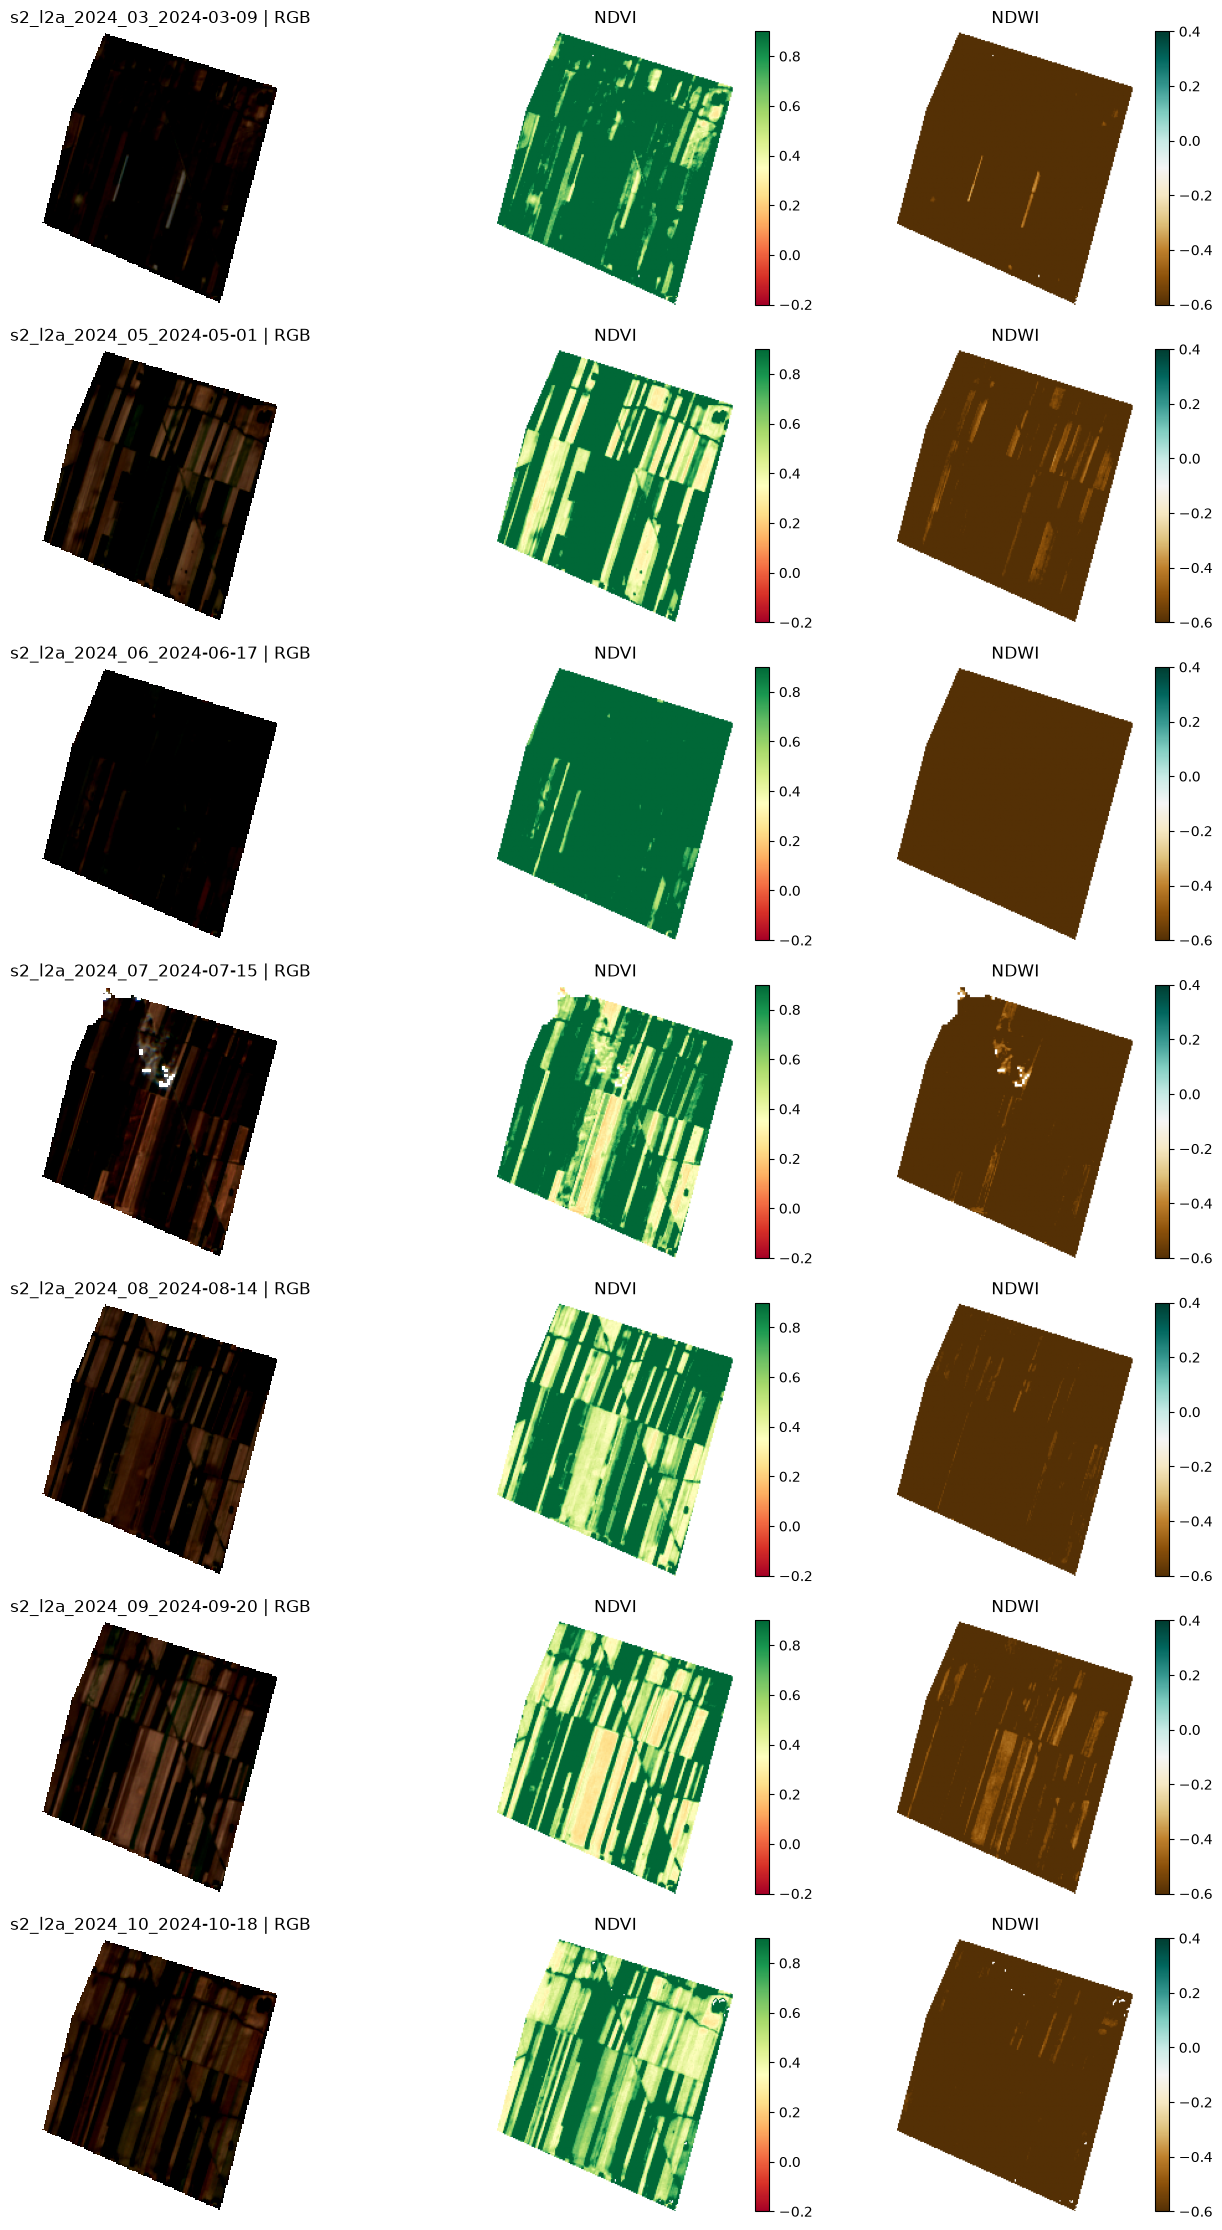

In [5]:
# Weryfikacja zapisanych rastrów 10-kanałowych i podgląd RGB / NDVI / NDWI
tif_files = sorted(OUT_DIR.glob(f"s2_l2a_{YEAR}_*.tif"))
if not tif_files:
    print(f"Brak plikow wynikowych w {OUT_DIR}")
else:
    n = len(tif_files)
    fig, axes = plt.subplots(n, 3, figsize=(13, 3.2 * n))
    if n == 1:
        axes = axes[np.newaxis, :]

    for row_idx, path in enumerate(tif_files):
        with rasterio.open(path) as src:
            arr = src.read()
            desc = tuple(src.descriptions)
        assert arr.shape[0] == len(BAND_NAMES) and desc == BAND_NAMES, (arr.shape, desc)
        doy_sin = float(np.nanmean(arr[8]))
        doy_cos = float(np.nanmean(arr[9]))
        print(f"{path.name}: shape={arr.shape}, NDVI_mean={np.nanmean(arr[6]):.3f}, NDWI_mean={np.nanmean(arr[7]):.3f}, DOY_SIN={doy_sin:.3f}, DOY_COS={doy_cos:.3f}")

        rgb = np.moveaxis(arr[:3], 0, -1)
        rgb_vis = np.clip(rgb / 0.30, 0.0, 1.0)
        axes[row_idx, 0].imshow(rgb_vis)
        axes[row_idx, 0].set_title(f"{path.stem} | RGB")

        im1 = axes[row_idx, 1].imshow(arr[6], cmap="RdYlGn", vmin=-0.2, vmax=0.9)
        axes[row_idx, 1].set_title("NDVI")
        plt.colorbar(im1, ax=axes[row_idx, 1], fraction=0.046)

        im2 = axes[row_idx, 2].imshow(arr[7], cmap="BrBG", vmin=-0.6, vmax=0.4)
        axes[row_idx, 2].set_title("NDWI")
        plt.colorbar(im2, ax=axes[row_idx, 2], fraction=0.046)

        for ax in axes[row_idx]:
            ax.set_axis_off()

    plt.tight_layout()
    plt.show()